<a href="https://colab.research.google.com/github/yannn-6243/PCD_Assignment01/blob/main/PCD_Assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#PCD Assignment 3


##Nama : Hadyan Althaf Baswara
##NIM : 25/559377/PA/23527

## Setup dan Fungsi Manual

In [77]:
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

BASE = "https://raw.githubusercontent.com/scikit-image/scikit-image/v0.19.3/skimage/data/"
BASE_CV = "https://raw.githubusercontent.com/opencv/opencv/4.9.0/samples/data/"

def get_image(fname, base=BASE):
    urllib.request.urlretrieve(base + fname, fname)
    img = plt.imread(fname)
    if img.dtype != np.uint8:
        img = (img * 255).round().astype(np.uint8)
    if img.ndim == 3:
        img = (0.299*img[..., 0] + 0.587*img[..., 1] + 0.114*img[..., 2]).astype(np.uint8)
    return img

def otsu_threshold(img):
    hist = np.bincount(img.ravel(), minlength=256).astype(np.float64)
    p = hist / img.size
    omega = np.cumsum(p)
    mu = np.cumsum(p * np.arange(256))
    denom = omega * (1 - omega)
    denom[denom == 0] = np.nan
    sigma_b = (mu[-1] * omega - mu) ** 2 / denom
    return int(np.nanargmax(sigma_b))

def segment_otsu(img, objek="terang"):
    t = otsu_threshold(img)
    mask = (img > t).astype(np.uint8)
    if objek == "gelap":
        mask = 1 - mask
    return mask, t

def square(n=3):
    return np.ones((n, n), dtype=np.uint8)

def disk(r):
    y, x = np.ogrid[-r:r+1, -r:r+1]
    return (x*x + y*y <= r*r).astype(np.uint8)

def dilation(mask, se):
    h, w = mask.shape; kh, kw = se.shape; ph, pw = kh//2, kw//2
    pad = np.pad(mask, ((ph, ph), (pw, pw)), constant_values=0)
    out = np.zeros_like(mask)
    for i in range(kh):
        for j in range(kw):
            if se[i, j]:
                out |= pad[i:i+h, j:j+w]
    return out

def erosion(mask, se, pad_val=0):
    h, w = mask.shape; kh, kw = se.shape; ph, pw = kh//2, kw//2
    pad = np.pad(mask, ((ph, ph), (pw, pw)), constant_values=pad_val)
    out = np.ones_like(mask)
    for i in range(kh):
        for j in range(kw):
            if se[i, j]:
                out &= pad[i:i+h, j:j+w]
    return out

def opening(mask, se): return dilation(erosion(mask, se), se)
def closing(mask, se): return erosion(dilation(mask, se), se, pad_val=1)

def label_components(mask):
    h, w = mask.shape
    labels = np.zeros((h, w), dtype=np.int32)
    cur, sizes = 0, []
    for y in range(h):
        for x in range(w):
            if mask[y, x] == 1 and labels[y, x] == 0:
                cur += 1; labels[y, x] = cur
                stack, size = [(y, x)], 0
                while stack:
                    cy, cx = stack.pop(); size += 1
                    for dy in (-1, 0, 1):
                        for dx in (-1, 0, 1):
                            ny, nx = cy+dy, cx+dx
                            if 0 <= ny < h and 0 <= nx < w and mask[ny, nx] == 1 and labels[ny, nx] == 0:
                                labels[ny, nx] = cur; stack.append((ny, nx))
                sizes.append(size)
    return labels, cur, sizes

def count_holes(mask):
    labels, n, _ = label_components(1 - mask)
    border = set(labels[0, :]) | set(labels[-1, :]) | set(labels[:, 0]) | set(labels[:, -1])
    border.discard(0)
    return n - len(border)

def thinning(mask):
    """Zhang-Suen thinning (manual, vectorized)."""
    img = np.pad(mask.astype(np.uint8), 1)
    changed = True
    while changed:
        changed = False
        for step in (0, 1):
            P2 = img[:-2, 1:-1]; P3 = img[:-2, 2:]; P4 = img[1:-1, 2:]; P5 = img[2:, 2:]
            P6 = img[2:, 1:-1]; P7 = img[2:, :-2]; P8 = img[1:-1, :-2]; P9 = img[:-2, :-2]
            C = img[1:-1, 1:-1]
            nb = [P2, P3, P4, P5, P6, P7, P8, P9]
            B = sum(n.astype(np.int16) for n in nb)
            A = sum(((nb[i] == 0) & (nb[(i+1) % 8] == 1)).astype(np.int16) for i in range(8))
            if step == 0:
                c1 = (P2 * P4 * P6) == 0; c2 = (P4 * P6 * P8) == 0
            else:
                c1 = (P2 * P4 * P8) == 0; c2 = (P2 * P6 * P8) == 0
            rm = (C == 1) & (B >= 2) & (B <= 6) & (A == 1) & c1 & c2
            if rm.any():
                img[1:-1, 1:-1][rm] = 0
                changed = True
    return img[1:-1, 1:-1]

def tampil(panels, judul):
    n = len(panels)
    h, w = panels[0][0].shape[:2]
    lebar = 5
    tinggi = lebar * h / w + 1
    fig, ax = plt.subplots(1, n, figsize=(lebar*n, tinggi))
    for a, (im, t) in zip(np.atleast_1d(ax), panels):
        a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
    fig.suptitle(judul, fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

##1. Segmentasi Otsu Thresholding

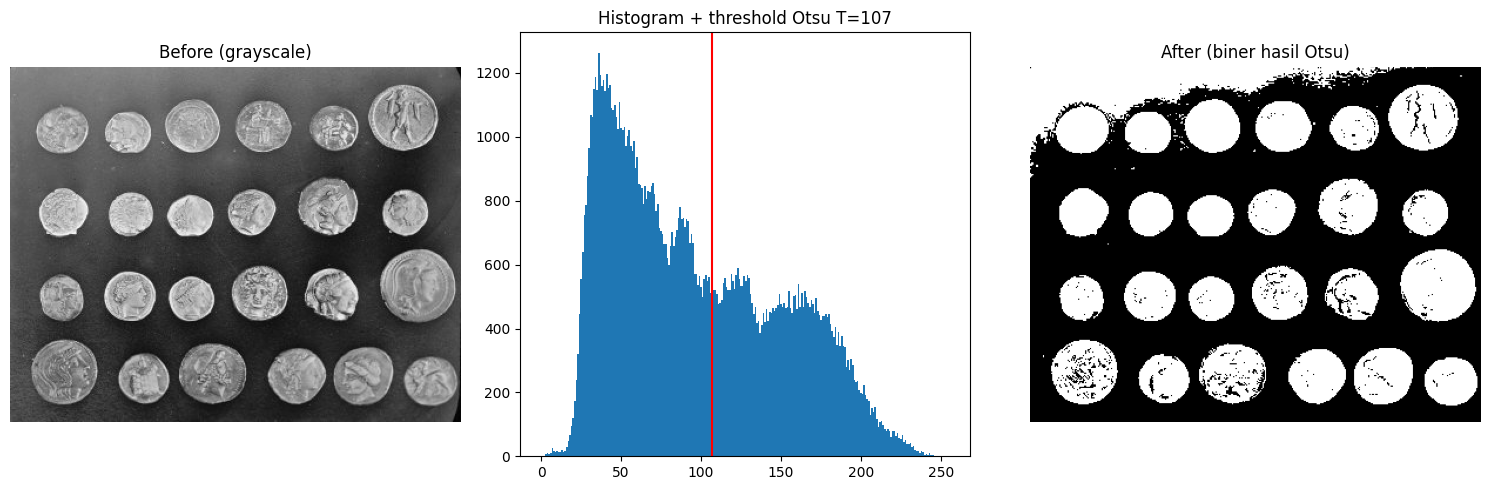

In [78]:
img = get_image("coins.png")
seg, T = segment_otsu(img, objek="terang")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("Before (grayscale)"); ax[0].axis("off")
ax[1].bar(range(256), np.bincount(img.ravel(), minlength=256), width=1)
ax[1].axvline(T, color="r"); ax[1].set_title(f"Histogram + threshold Otsu T={T}")
ax[2].imshow(seg, cmap="gray"); ax[2].set_title("After (biner hasil Otsu)"); ax[2].axis("off")
plt.tight_layout(); plt.show()

##2. Erosi

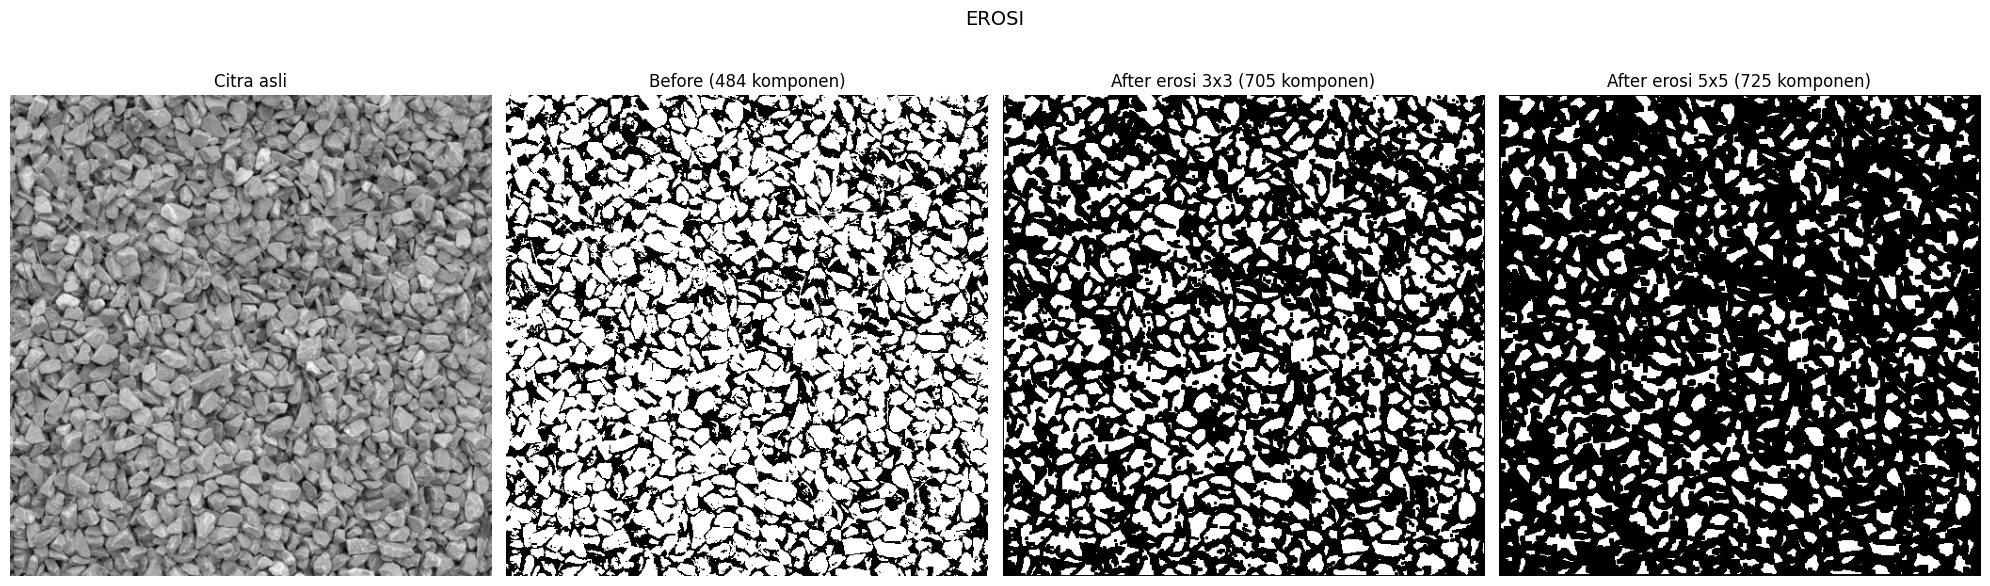

In [79]:
img = get_image("gravel.png")
seg, T = segment_otsu(img, "terang")
e3, e5 = erosion(seg, square(3)), erosion(seg, square(5))
n0, n3, n5 = (label_components(m)[1] for m in (seg, e3, e5))

tampil([(img, "Citra asli"), (seg, f"Before ({n0} komponen)"),
        (e3, f"After erosi 3x3 ({n3} komponen)"),
        (e5, f"After erosi 5x5 ({n5} komponen)")],
       "EROSI")

##3. Dilasi

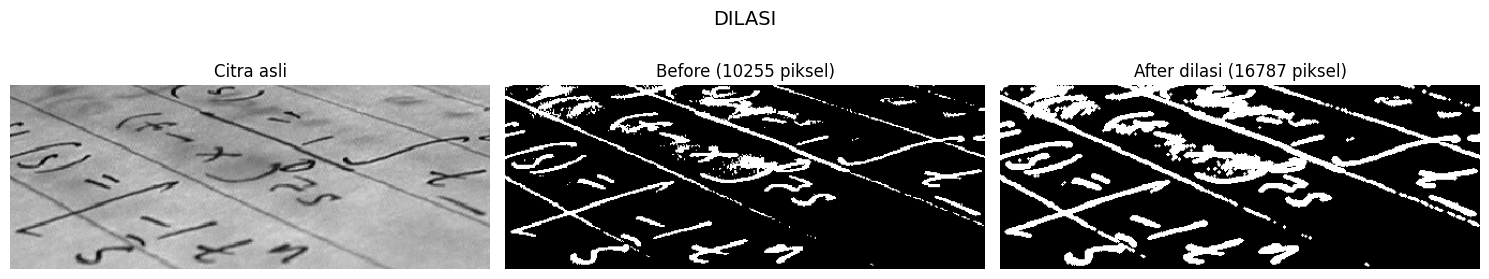

In [80]:
img = get_image("text.png")
seg, T = segment_otsu(img, "gelap")
se_plus = np.array([[0,1,0],[1,1,1],[0,1,0]], dtype=np.uint8)   # SE tanda plus seperti di slide
res = dilation(seg, se_plus)

tampil([(img, "Citra asli"), (seg, f"Before ({int(seg.sum())} piksel)"),
        (res, f"After dilasi ({int(res.sum())} piksel)")],
       "DILASI")

##4. Opening

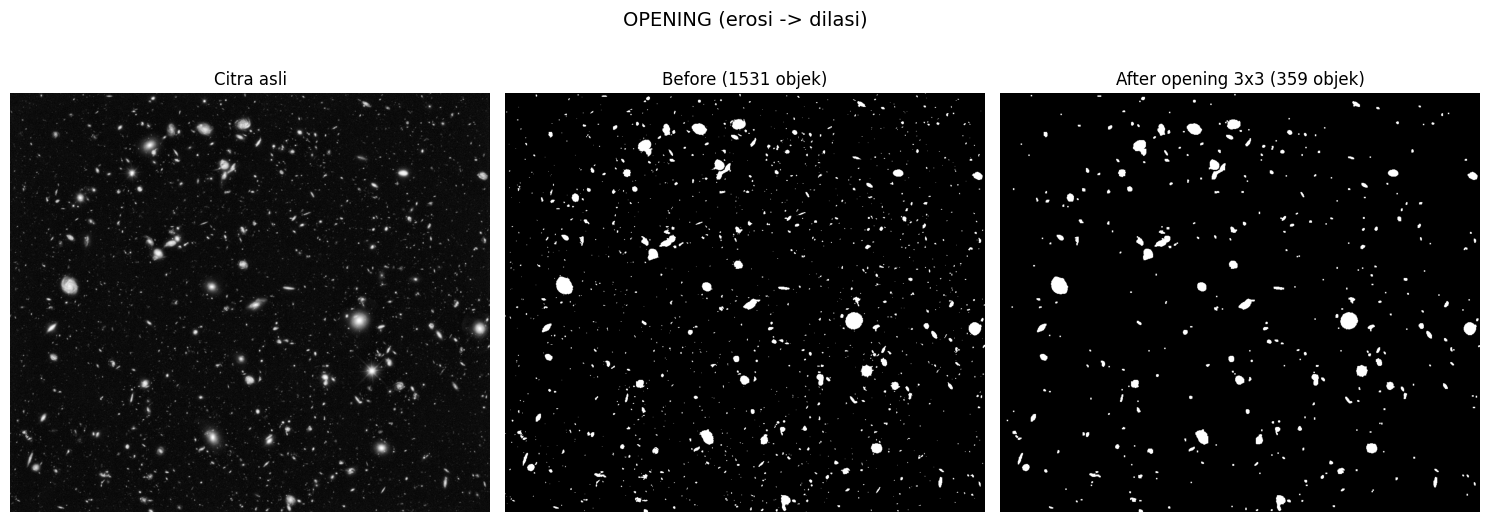

In [87]:
img = get_image("hubble_deep_field.jpg")
seg, T = segment_otsu(img, "terang")
res = opening(seg, square(3))
n_b, n_a = label_components(seg)[1], label_components(res)[1]

tampil([(img, "Citra asli"), (seg, f"Before ({n_b} objek)"),
        (res, f"After opening 3x3 ({n_a} objek)")],
       "OPENING (erosi -> dilasi)")

##5. Closing

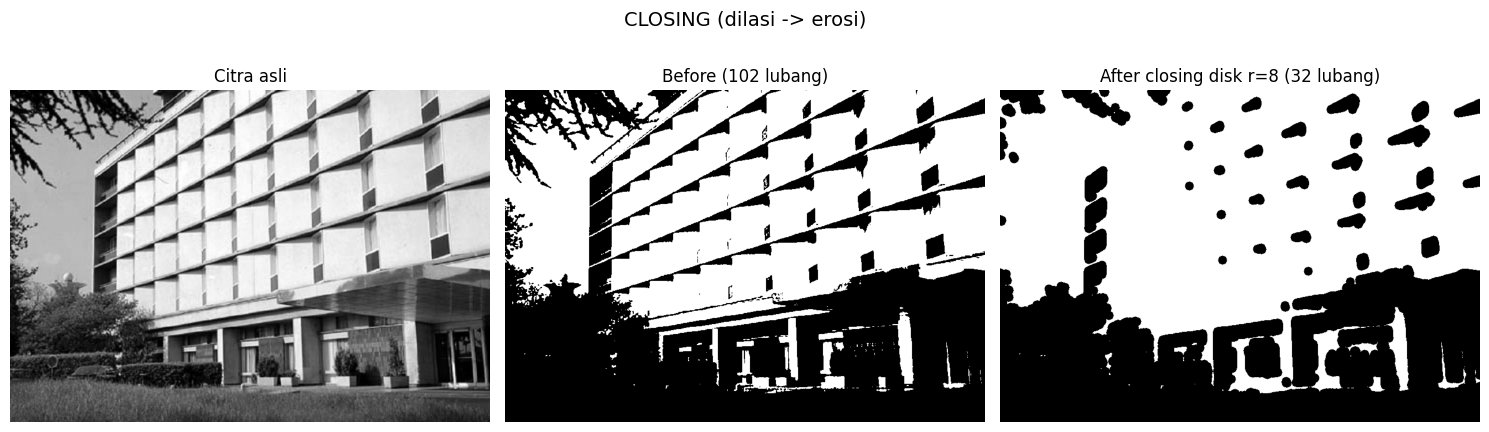

In [86]:
img = get_image("building.jpg", BASE_CV)
seg, T = segment_otsu(img, "terang")
res = closing(seg, disk(8))
h_b, h_a = count_holes(seg), count_holes(res)
tampil([(img, "Citra asli"), (seg, f"Before ({h_b} lubang)"),
        (res, f"After closing disk r=8 ({h_a} lubang)")],
       "CLOSING (dilasi -> erosi)")

##6. Deteksi Tepi dengan Dilasi

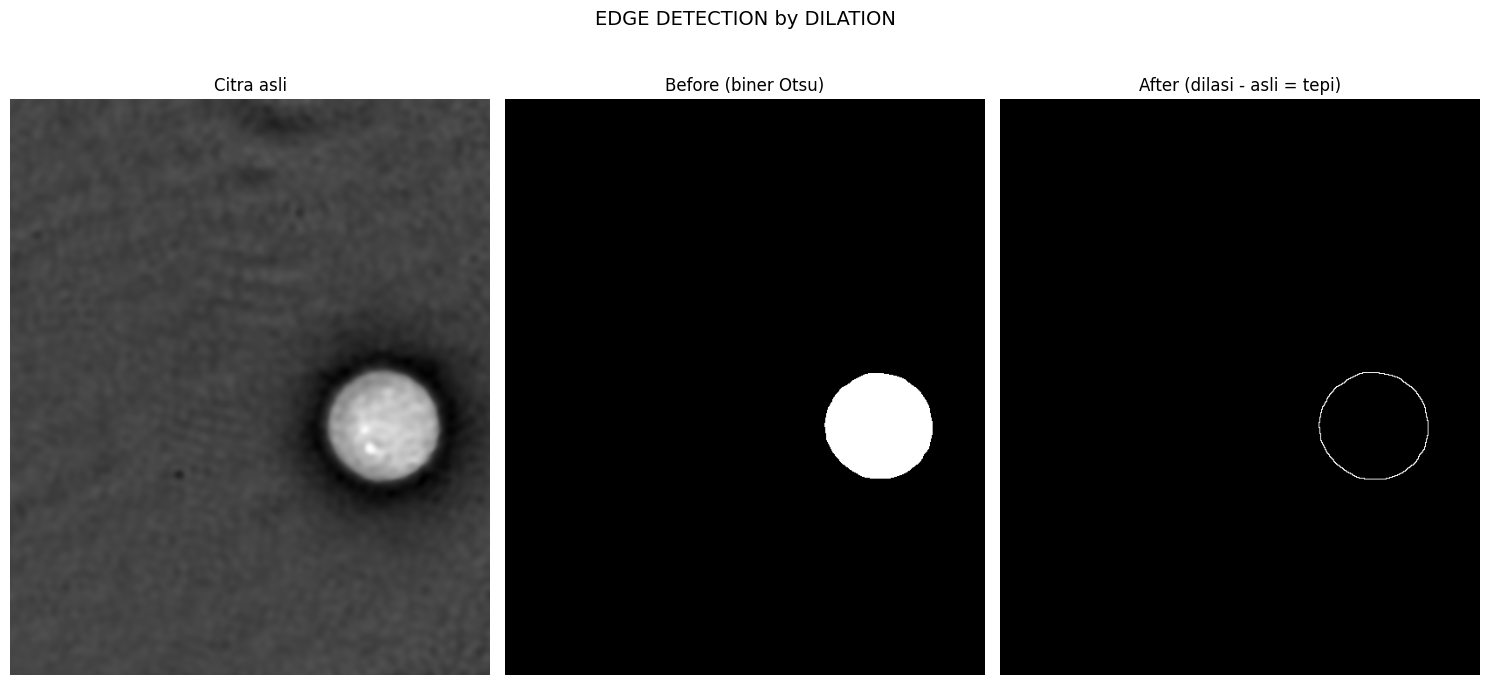

In [89]:
img = get_image("cell.png")
seg, T = segment_otsu(img, "terang")
edge = dilation(seg, square(3)) - seg

tampil([(img, "Citra asli"), (seg, "Before (biner Otsu)"), (edge, "After (dilasi - asli = tepi)")],
       "EDGE DETECTION by DILATION")

##7. Thinning (Skeletonization)

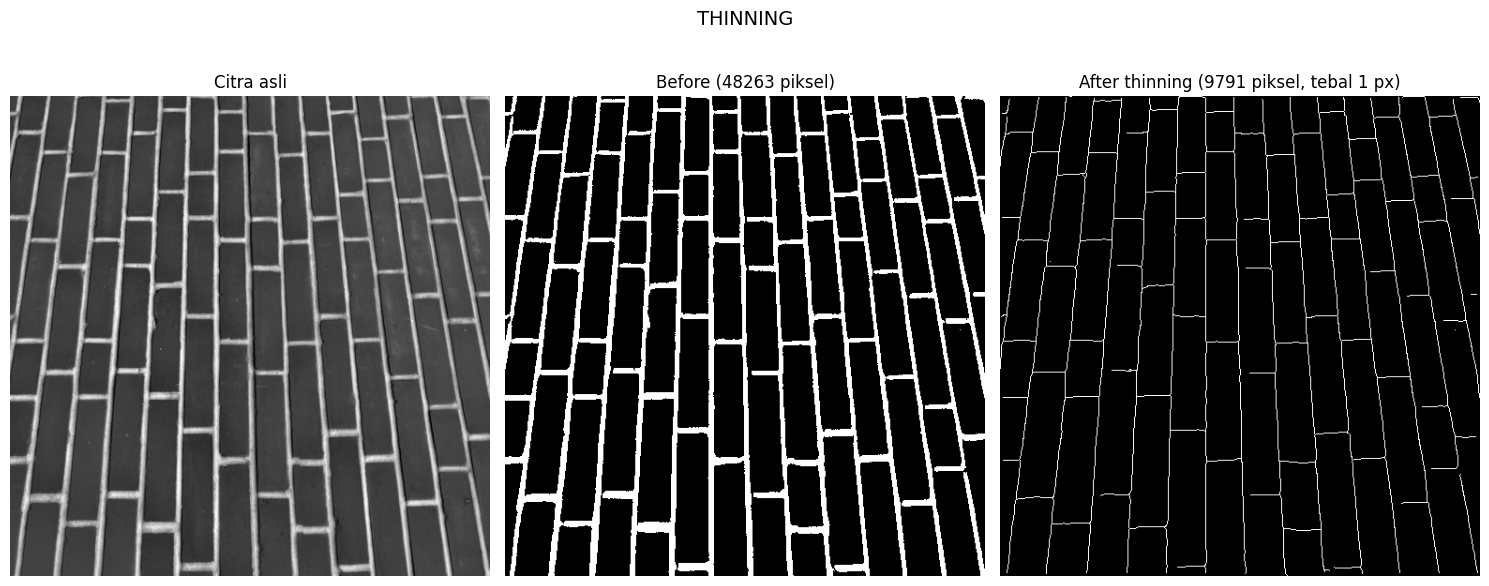

In [84]:
img = get_image("brick.png")
seg, T = segment_otsu(img, "terang")
skel = thinning(seg)

tampil([(img, "Citra asli"), (seg, f"Before ({int(seg.sum())} piksel)"),
        (skel, f"After thinning ({int(skel.sum())} piksel, tebal 1 px)")], "THINNING")

##8. Segmentasi Morfologi

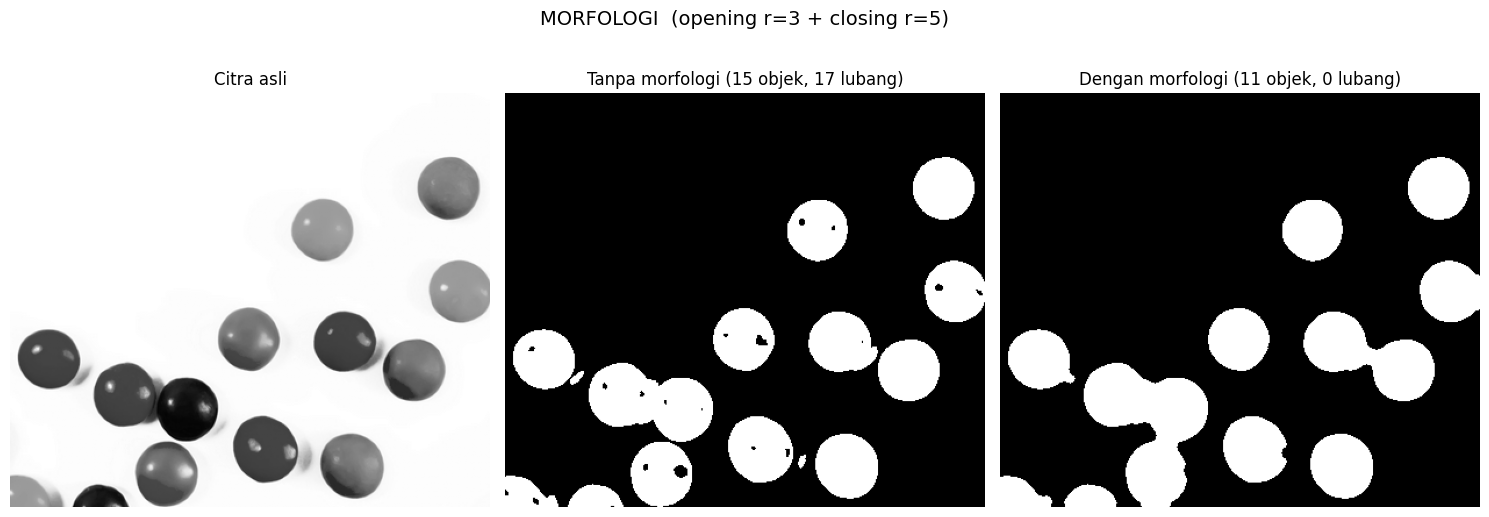

                               Tanpa    Dengan
Jumlah objek                      15        11
Objek kecil (<100 px)              2         0
Jumlah lubang                     17         0
Piksel foreground              28951     29426


In [90]:
img = get_image("smarties.png", BASE_CV)

seg, T = segment_otsu(img, "gelap")
seg_m = closing(opening(seg, disk(3)), disk(5))
_, n1, s1 = label_components(seg); _, n2, s2 = label_components(seg_m)
h1, h2 = count_holes(seg), count_holes(seg_m)

tampil([(img, "Citra asli"),
        (seg, f"Tanpa morfologi ({n1} objek, {h1} lubang)"),
        (seg_m, f"Dengan morfologi ({n2} objek, {h2} lubang)")],
       "MORFOLOGI  (opening r=3 + closing r=5)")
print(f"{'':26}{'Tanpa':>10}{'Dengan':>10}")
print(f"{'Jumlah objek':26}{n1:>10}{n2:>10}")
print(f"{'Objek kecil (<100 px)':26}{sum(s<100 for s in s1):>10}{sum(s<100 for s in s2):>10}")
print(f"{'Jumlah lubang':26}{h1:>10}{h2:>10}")
print(f"{'Piksel foreground':26}{int(seg.sum()):>10}{int(seg_m.sum()):>10}")